# IPL Score Prediction using Machine Learning

This Machine Learning model adapts a Regression Approach to predict the score of the First Inning of an IPL Match.

# Import Necessary Libraries

In [19]:
import pandas as pd
import numpy as np
import pickle
from pathlib import Path

from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor

# 1. Load the dataset
data_path = Path("ipl_data.csv")
df = pd.read_csv(data_path)

print("Dataset loaded:", df.shape)

# 2. Keep the teams supported by the Streamlit application
teams = [
    "Chennai Super Kings",
    "Delhi Daredevils",
    "Kings XI Punjab",
    "Kolkata Knight Riders",
    "Mumbai Indians",
    "Rajasthan Royals",
    "Royal Challengers Bangalore",
    "Sunrisers Hyderabad"
]

# 3. Clean the dataset
df = df[
    df["bat_team"].isin(teams)
    & df["bowl_team"].isin(teams)
    & (df["overs"] >= 5.0)
].copy()

features = [
    "bat_team",
    "bowl_team",
    "runs",
    "wickets",
    "overs",
    "runs_last_5",
    "wickets_last_5"
]

df = df.dropna(subset=features + ["total"])

X = df[features]
y = df["total"]

print("Cleaned dataset:", X.shape)

# 4. Encode the batting and bowling teams
encoder = OneHotEncoder(
    categories=[teams, teams],
    handle_unknown="ignore",
    sparse_output=False
)

transformer = ColumnTransformer(
    transformers=[
        ("teams", encoder, ["bat_team", "bowl_team"])
    ],
    remainder="passthrough"
)

X_encoded = transformer.fit_transform(X)

print("Encoded feature shape:", X_encoded.shape)

# 5. Train the Random Forest model
forest = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

forest.fit(X_encoded, y)

print("Model training completed!")

# 6. Save the model in the project folder
model_path = Path.cwd() / "ml_model.pkl"

with open(model_path, "wb") as file:
    pickle.dump(forest, file)

print("Model saved:", model_path)
print("File exists:", model_path.exists())
print("File size:", model_path.stat().st_size, "bytes")

Dataset loaded: (76014, 15)
Cleaned dataset: (40108, 7)
Encoded feature shape: (40108, 21)
Model training completed!
Model saved: c:\Users\Sahil Dhumal\Downloads\IPLScorePredictor-main\IPLScorePredictor-main\ml_model.pkl
File exists: True
File size: 144203284 bytes


In [18]:
import os

print("Notebook directory:", os.getcwd())
print("Random Forest trained:", "forest" in globals())

Notebook directory: c:\Users\Sahil Dhumal\Downloads\IPLScorePredictor-main\IPLScorePredictor-main
Random Forest trained: False


In [1]:
import sys
print("Notebook Python:", sys.executable)

%pip install pandas numpy seaborn matplotlib scikit-learn xgboost

Notebook Python: c:\Program Files\Python314\python.exe
Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

print("SUCCESS: All libraries are working!")

SUCCESS: All libraries are working!


Load the dataset

In [3]:
#Importing dataset
ipl_df = pd.read_csv('ipl_data.csv')
print(f"Dataset successfully Imported of Shape : {ipl_df.shape}")

Dataset successfully Imported of Shape : (76014, 15)


# Exploratory Data Analysis

In [4]:
# First 5 Columns Data
ipl_df.head()

,mid,date,venue,bat_team,bowl_team,batsman,bowler,runs,wickets,overs,runs_last_5,wickets_last_5,striker,non-striker,total
0,1,2008-04-18,M Chinnaswamy Stadium,Kolkata Knight Riders,Royal Challengers Bangalore,SC Ganguly,P Kumar,1,0,0.1,1,0,0,0,222
1,1,2008-04-18,M Chinnaswamy Stadium,Kolkata Knight Riders,Royal Challengers Bangalore,BB McCullum,P Kumar,1,0,0.2,1,0,0,0,222
2,1,2008-04-18,M Chinnaswamy Stadium,Kolkata Knight Riders,Royal Challengers Bangalore,BB McCullum,P Kumar,2,0,0.2,2,0,0,0,222
3,1,2008-04-18,M Chinnaswamy Stadium,Kolkata Knight Riders,Royal Challengers Bangalore,BB McCullum,P Kumar,2,0,0.3,2,0,0,0,222
4,1,2008-04-18,M Chinnaswamy Stadium,Kolkata Knight Riders,Royal Challengers Bangalore,BB McCullum,P Kumar,2,0,0.4,2,0,0,0,222


In [5]:
# Describing the ipl_dfset
ipl_df.describe()

,mid,runs,wickets,overs,runs_last_5,wickets_last_5,striker,non-striker,total
count,76014.000000,76014.000000,76014.000000,76014.000000,76014.000000,76014.000000,76014.000000,76014.000000,76014.000000
mean,308.627740,74.889349,2.415844,9.783068,33.216434,1.120307,24.962283,8.869287,160.901452
std,178.156878,48.823327,2.015207,5.772587,14.914174,1.053343,20.079752,10.795742,29.246231
min,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,67.000000
25%,154.000000,34.000000,1.000000,4.600000,24.000000,0.000000,10.000000,1.000000,142.000000
50%,308.000000,70.000000,2.000000,9.600000,34.000000,1.000000,20.000000,5.000000,162.000000
75%,463.000000,111.000000,4.000000,14.600000,43.000000,2.000000,35.000000,13.000000,181.000000
max,617.000000,263.000000,10.000000,19.600000,113.000000,7.000000,175.000000,109.000000,263.000000


In [6]:
# Information about Each Column
ipl_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 76014 entries, 0 to 76013
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   mid             76014 non-null  int64  
 1   date            76014 non-null  str    
 2   venue           76014 non-null  str    
 3   bat_team        76014 non-null  str    
 4   bowl_team       76014 non-null  str    
 5   batsman         76014 non-null  str    
 6   bowler          76014 non-null  str    
 7   runs            76014 non-null  int64  
 8   wickets         76014 non-null  int64  
 9   overs           76014 non-null  float64
 10  runs_last_5     76014 non-null  int64  
 11  wickets_last_5  76014 non-null  int64  
 12  striker         76014 non-null  int64  
 13  non-striker     76014 non-null  int64  
 14  total           76014 non-null  int64  
dtypes: float64(1), int64(8), str(6)
memory usage: 8.7 MB


In [7]:
# Number of Unique Values in each column
ipl_df.nunique()

mid               617
date              442
venue              35
bat_team           14
bowl_team          14
batsman           411
bowler            329
runs              252
wickets            11
overs             140
runs_last_5       102
wickets_last_5      8
striker           155
non-striker        88
total             138
dtype: int64

In [8]:
# ipl_df types of all Columns
ipl_df.dtypes

mid                 int64
date                  str
venue                 str
bat_team              str
bowl_team             str
batsman               str
bowler                str
runs                int64
wickets             int64
overs             float64
runs_last_5         int64
wickets_last_5      int64
striker             int64
non-striker         int64
total               int64
dtype: object

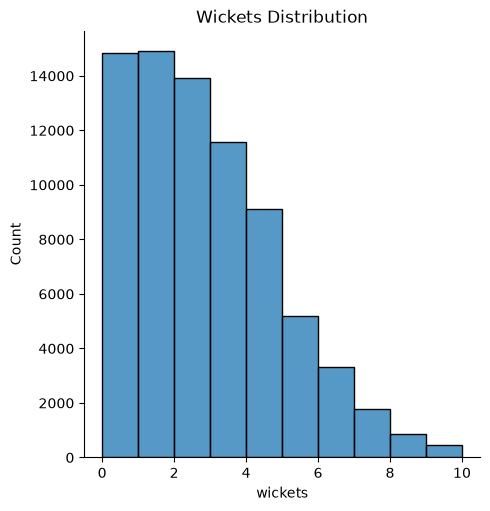

In [9]:
#Wickets Distribution
sns.displot(ipl_df['wickets'],kde=False,bins=10)
plt.title("Wickets Distribution")

plt.show()

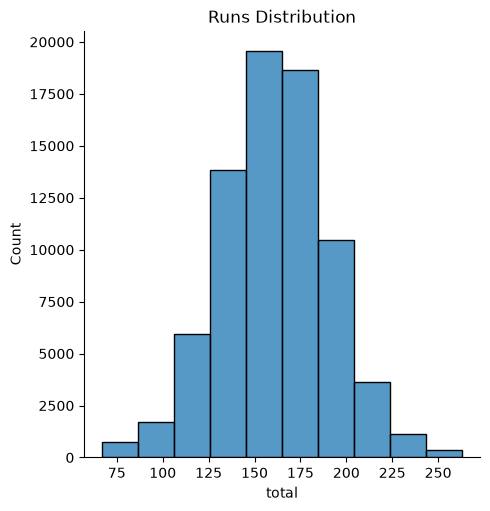

In [10]:
#Runs Distribution
sns.displot(ipl_df['total'],kde=False,bins=10)
plt.title("Runs Distribution")

plt.show()

# Data Cleaning

#### Removing Irrelevant Data colunms

In [11]:
# Names of all columns
ipl_df.columns

Index(['mid', 'date', 'venue', 'bat_team', 'bowl_team', 'batsman', 'bowler',
       'runs', 'wickets', 'overs', 'runs_last_5', 'wickets_last_5', 'striker',
       'non-striker', 'total'],
      dtype='str')

Here, we can see that columns _['mid', 'date', 'venue', 'batsman', 'bowler', 'striker', 'non-striker']_ won't provide any relevant information for our model to train

In [12]:
irrelevant = ['mid', 'date', 'venue','batsman', 'bowler', 'striker', 'non-striker']
print(f'Before Removing Irrelevant Columns : {ipl_df.shape}')
ipl_df = ipl_df.drop(irrelevant, axis=1) # Drop Irrelevant Columns
print(f'After Removing Irrelevant Columns : {ipl_df.shape}')
ipl_df.head()

Before Removing Irrelevant Columns : (76014, 15)
After Removing Irrelevant Columns : (76014, 8)


,bat_team,bowl_team,runs,wickets,overs,runs_last_5,wickets_last_5,total
0,Kolkata Knight Riders,Royal Challengers Bangalore,1,0,0.1,1,0,222
1,Kolkata Knight Riders,Royal Challengers Bangalore,1,0,0.2,1,0,222
2,Kolkata Knight Riders,Royal Challengers Bangalore,2,0,0.2,2,0,222
3,Kolkata Knight Riders,Royal Challengers Bangalore,2,0,0.3,2,0,222
4,Kolkata Knight Riders,Royal Challengers Bangalore,2,0,0.4,2,0,222


#### Keeping only Consistent Teams 


In [13]:
# Define Consistent Teams
const_teams = ['Kolkata Knight Riders', 'Chennai Super Kings', 'Rajasthan Royals',
              'Mumbai Indians', 'Kings XI Punjab', 'Royal Challengers Bangalore',
              'Delhi Daredevils', 'Sunrisers Hyderabad']

In [14]:
print(f'Before Removing Inconsistent Teams : {ipl_df.shape}')
ipl_df = ipl_df[(ipl_df['bat_team'].isin(const_teams)) & (ipl_df['bowl_team'].isin(const_teams))]
print(f'After Removing Irrelevant Columns : {ipl_df.shape}')
print(f"Consistent Teams : \n{ipl_df['bat_team'].unique()}")
ipl_df.head()

Before Removing Inconsistent Teams : (76014, 8)
After Removing Irrelevant Columns : (53811, 8)
Consistent Teams : 
<StringArray>
[      'Kolkata Knight Riders',         'Chennai Super Kings',
            'Rajasthan Royals',              'Mumbai Indians',
             'Kings XI Punjab', 'Royal Challengers Bangalore',
            'Delhi Daredevils',         'Sunrisers Hyderabad']
Length: 8, dtype: str


,bat_team,bowl_team,runs,wickets,overs,runs_last_5,wickets_last_5,total
0,Kolkata Knight Riders,Royal Challengers Bangalore,1,0,0.1,1,0,222
1,Kolkata Knight Riders,Royal Challengers Bangalore,1,0,0.2,1,0,222
2,Kolkata Knight Riders,Royal Challengers Bangalore,2,0,0.2,2,0,222
3,Kolkata Knight Riders,Royal Challengers Bangalore,2,0,0.3,2,0,222
4,Kolkata Knight Riders,Royal Challengers Bangalore,2,0,0.4,2,0,222


#### Remove First 5 Overs of every match

In [15]:
print(f'Before Removing Overs : {ipl_df.shape}')
ipl_df = ipl_df[ipl_df['overs'] >= 5.0]
print(f'After Removing Overs : {ipl_df.shape}')
ipl_df.head()

Before Removing Overs : (53811, 8)
After Removing Overs : (40108, 8)


,bat_team,bowl_team,runs,wickets,overs,runs_last_5,wickets_last_5,total
32,Kolkata Knight Riders,Royal Challengers Bangalore,61,0,5.1,59,0,222
33,Kolkata Knight Riders,Royal Challengers Bangalore,61,1,5.2,59,1,222
34,Kolkata Knight Riders,Royal Challengers Bangalore,61,1,5.3,59,1,222
35,Kolkata Knight Riders,Royal Challengers Bangalore,61,1,5.4,59,1,222
36,Kolkata Knight Riders,Royal Challengers Bangalore,61,1,5.5,58,1,222


Plotting a Correlation Matrix of current data

In [16]:
from seaborn import heatmap
heatmap(data=ipl_df.corr(), annot=True)

ValueError: could not convert string to float: 'Kolkata Knight Riders'

# Data Preprocessing and Encoding

#### Performing Label Encoding

In [ ]:
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
le = LabelEncoder()
for col in ['bat_team', 'bowl_team']:
  ipl_df[col] = le.fit_transform(ipl_df[col])
ipl_df.head()

,bat_team,bowl_team,runs,wickets,overs,runs_last_5,wickets_last_5,total
32,3,6,61,0,5.1,59,0,222
33,3,6,61,1,5.2,59,1,222
34,3,6,61,1,5.3,59,1,222
35,3,6,61,1,5.4,59,1,222
36,3,6,61,1,5.5,58,1,222


#### Performing One Hot Encoding and Column Transformation

In [ ]:
from sklearn.compose import ColumnTransformer
columnTransformer = ColumnTransformer([('encoder', 
                                        OneHotEncoder(), 
                                        [0, 1])], 
                                      remainder='passthrough')

In [ ]:
ipl_df = np.array(columnTransformer.fit_transform(ipl_df))

Save the Numpy Array in a new DataFrame with transformed columns

In [ ]:
cols = ['batting_team_Chennai Super Kings', 'batting_team_Delhi Daredevils', 'batting_team_Kings XI Punjab',
              'batting_team_Kolkata Knight Riders', 'batting_team_Mumbai Indians', 'batting_team_Rajasthan Royals',
              'batting_team_Royal Challengers Bangalore', 'batting_team_Sunrisers Hyderabad',
              'bowling_team_Chennai Super Kings', 'bowling_team_Delhi Daredevils', 'bowling_team_Kings XI Punjab',
              'bowling_team_Kolkata Knight Riders', 'bowling_team_Mumbai Indians', 'bowling_team_Rajasthan Royals',
              'bowling_team_Royal Challengers Bangalore', 'bowling_team_Sunrisers Hyderabad', 'runs', 'wickets', 'overs',
       'runs_last_5', 'wickets_last_5', 'total']
df = pd.DataFrame(ipl_df, columns=cols)

In [ ]:
# Encoded Data
df.head()

,batting_team_Chennai Super Kings,batting_team_Delhi Daredevils,batting_team_Kings XI Punjab,batting_team_Kolkata Knight Riders,batting_team_Mumbai Indians,batting_team_Rajasthan Royals,batting_team_Royal Challengers Bangalore,batting_team_Sunrisers Hyderabad,bowling_team_Chennai Super Kings,bowling_team_Delhi Daredevils,...,bowling_team_Mumbai Indians,bowling_team_Rajasthan Royals,bowling_team_Royal Challengers Bangalore,bowling_team_Sunrisers Hyderabad,runs,wickets,overs,runs_last_5,wickets_last_5,total
0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,61.0,0.0,5.1,59.0,0.0,222.0
1,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,61.0,1.0,5.2,59.0,1.0,222.0
2,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,61.0,1.0,5.3,59.0,1.0,222.0
3,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,61.0,1.0,5.4,59.0,1.0,222.0
4,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,61.0,1.0,5.5,58.0,1.0,222.0


# Model Building

## Prepare Train and Test Data

In [ ]:
features = df.drop(['total'], axis=1)
labels = df['total']

In [ ]:
from sklearn.model_selection import train_test_split
train_features, test_features, train_labels, test_labels = train_test_split(features, labels, test_size=0.20, shuffle=True)
print(f"Training Set : {train_features.shape}\nTesting Set : {test_features.shape}")

Training Set : (32086, 21)
Testing Set : (8022, 21)


## ML  Algorithms

In [ ]:
models = dict()

#### 1. Decision Tree Regressor

In [ ]:
from sklearn.tree import DecisionTreeRegressor
tree = DecisionTreeRegressor()
# Train Model
tree.fit(train_features, train_labels)

DecisionTreeRegressor()

In [ ]:
# Evaluate Model
train_score_tree = str(tree.score(train_features, train_labels) * 100)
test_score_tree = str(tree.score(test_features, test_labels) * 100)
print(f'Train Score : {train_score_tree[:5]}%\nTest Score : {test_score_tree[:5]}%')
models["tree"] = test_score_tree

Train Score : 99.98%
Test Score : 86.81%


In [ ]:
from sklearn.metrics import mean_absolute_error as mae, mean_squared_error as mse
print("---- Decision Tree Regressor - Model Evaluation ----")
print("Mean Absolute Error (MAE): {}".format(mae(test_labels, tree.predict(test_features))))
print("Mean Squared Error (MSE): {}".format(mse(test_labels, tree.predict(test_features))))
print("Root Mean Squared Error (RMSE): {}".format(np.sqrt(mse(test_labels, tree.predict(test_features)))))

---- Decision Tree Regressor - Model Evaluation ----
Mean Absolute Error (MAE): 3.7974320618299675
Mean Squared Error (MSE): 117.53745948641236
Root Mean Squared Error (RMSE): 10.841469433910348


#### Linear Regression

In [ ]:
from sklearn.linear_model import LinearRegression
linreg = LinearRegression()
# Train Model
linreg.fit(train_features, train_labels)

LinearRegression()

In [ ]:
# Evaluate Model
train_score_linreg = str(linreg.score(train_features, train_labels) * 100)
test_score_linreg = str(linreg.score(test_features, test_labels) * 100)
print(f'Train Score : {train_score_linreg[:5]}%\nTest Score : {test_score_linreg[:5]}%')
models["linreg"] = test_score_linreg

Train Score : 65.88%
Test Score : 66.05%


In [ ]:
print("---- Linear Regression - Model Evaluation ----")
print("Mean Absolute Error (MAE): {}".format(mae(test_labels, linreg.predict(test_features))))
print("Mean Squared Error (MSE): {}".format(mse(test_labels, linreg.predict(test_features))))
print("Root Mean Squared Error (RMSE): {}".format(np.sqrt(mse(test_labels, linreg.predict(test_features)))))

---- Linear Regression - Model Evaluation ----
Mean Absolute Error (MAE): 13.11558631381687
Mean Squared Error (MSE): 302.5207859338951
Root Mean Squared Error (RMSE): 17.393124674246867


#### Random Forest Regression

In [ ]:
from sklearn.ensemble import RandomForestRegressor
forest = RandomForestRegressor()
# Train Model
forest.fit(train_features, train_labels)

RandomForestRegressor()

In [ ]:
# Evaluate Model
train_score_forest = str(forest.score(train_features, train_labels)*100)
test_score_forest = str(forest.score(test_features, test_labels)*100)
print(f'Train Score : {train_score_forest[:5]}%\nTest Score : {test_score_forest[:5]}%')
models["forest"] = test_score_forest

Train Score : 99.01%
Test Score : 94.03%


In [ ]:
print("---- Random Forest Regression - Model Evaluation ----")
print("Mean Absolute Error (MAE): {}".format(mae(test_labels, forest.predict(test_features))))
print("Mean Squared Error (MSE): {}".format(mse(test_labels, forest.predict(test_features))))
print("Root Mean Squared Error (RMSE): {}".format(np.sqrt(mse(test_labels, forest.predict(test_features)))))

---- Random Forest Regression - Model Evaluation ----
Mean Absolute Error (MAE): 4.429588652040223
Mean Squared Error (MSE): 53.15807637397504
Root Mean Squared Error (RMSE): 7.290958536020833


#### Support Vector Machine

In [ ]:
from sklearn.svm import SVR
svm = SVR()
# Train Model
svm.fit(train_features, train_labels)

SVR()

In [ ]:
train_score_svm = str(svm.score(train_features, train_labels)*100)
test_score_svm = str(svm.score(test_features, test_labels)*100)
print(f'Train Score : {train_score_svm[:5]}%\nTest Score : {test_score_svm[:5]}%')
models["svm"] = test_score_svm 

Train Score : 57.48%
Test Score : 57.35%


In [ ]:
print("---- Support Vector Regression - Model Evaluation ----")
print("Mean Absolute Error (MAE): {}".format(mae(test_labels, svm.predict(test_features))))
print("Mean Squared Error (MSE): {}".format(mse(test_labels, svm.predict(test_features))))
print("Root Mean Squared Error (RMSE): {}".format(np.sqrt(mse(test_labels, svm.predict(test_features)))))

---- Support Vector Regression - Model Evaluation ----
Mean Absolute Error (MAE): 14.81715661261272
Mean Squared Error (MSE): 380.0384487713315
Root Mean Squared Error (RMSE): 19.494574854849528


#### XGBoost

In [ ]:
from xgboost import XGBRegressor
xgb = XGBRegressor()
# Train Model
xgb.fit(train_features, train_labels)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             gamma=None, gpu_id=None, grow_policy=None, importance_type=None,
             interaction_constraints=None, learning_rate=None, max_bin=None,
             max_cat_threshold=None, max_cat_to_onehot=None,
             max_delta_step=None, max_depth=None, max_leaves=None,
             min_child_weight=None, missing=nan, monotone_constraints=None,
             n_estimators=100, n_jobs=None, num_parallel_tree=None,
             predictor=None, random_state=None, ...)

In [ ]:
train_score_xgb = str(xgb.score(train_features, train_labels)*100)
test_score_xgb = str(xgb.score(test_features, test_labels)*100)
print(f'Train Score : {train_score_xgb[:5]}%\nTest Score : {test_score_xgb[:5]}%')
models["xgb"] = test_score_xgb

Train Score : 88.69%
Test Score : 85.12%


In [ ]:
print("---- XGB Regression - Model Evaluation ----")
print("Mean Absolute Error (MAE): {}".format(mae(test_labels, xgb.predict(test_features))))
print("Mean Squared Error (MSE): {}".format(mse(test_labels, xgb.predict(test_features))))
print("Root Mean Squared Error (RMSE): {}".format(np.sqrt(mse(test_labels, xgb.predict(test_features)))))

---- XGB Regression - Model Evaluation ----
Mean Absolute Error (MAE): 8.352449687214987
Mean Squared Error (MSE): 132.51928077369277
Root Mean Squared Error (RMSE): 11.51170190604729


KNR

In [ ]:
from sklearn.neighbors import KNeighborsRegressor
knr = KNeighborsRegressor()
# Train Model
knr.fit(train_features, train_labels)

KNeighborsRegressor()

In [ ]:
train_score_knr = str(knr.score(train_features, train_labels)*100)
test_score_knr = str(knr.score(test_features, test_labels)*100)
print(f'Train Score : {train_score_knr[:5]}%\nTest Score : {test_score_knr[:5]}%')
models["knr"] = test_score_knr

Train Score : 86.80%
Test Score : 77.52%


In [ ]:
print("---- KNR - Model Evaluation ----")
print("Mean Absolute Error (MAE): {}".format(mae(test_labels, knr.predict(test_features))))
print("Mean Squared Error (MSE): {}".format(mse(test_labels, knr.predict(test_features))))
print("Root Mean Squared Error (RMSE): {}".format(np.sqrt(mse(test_labels, knr.predict(test_features)))))

---- KNR - Model Evaluation ----
Mean Absolute Error (MAE): 9.86182996758913
Mean Squared Error (MSE): 200.2784642233857
Root Mean Squared Error (RMSE): 14.151977396229324


## Best Model 

<BarContainer object of 6 artists>

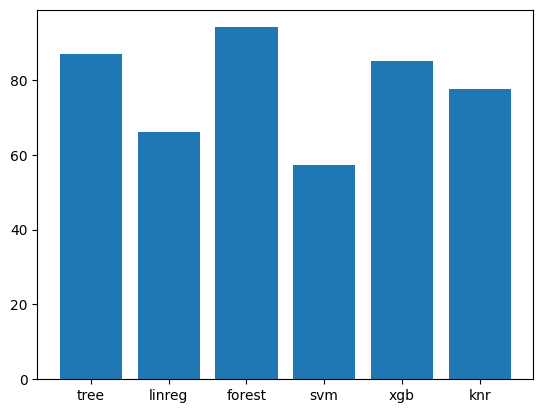

In [ ]:
import matplotlib.pyplot as plt 
model_names = list(models.keys())
accuracy = list(map(float, models.values()))
# creating the bar plot
plt.bar(model_names, accuracy)

From above, we can see that **Random Forest** performed the best, closely followed by **Decision Tree** and **KNR**. So we will be choosing Random Forest for the final model

# Predictions

In [ ]:
def score_predict(batting_team, bowling_team, runs, wickets, overs, runs_last_5, wickets_last_5, model=forest):
  prediction_array = []
  # Batting Team
  if batting_team == 'Chennai Super Kings':
    prediction_array = prediction_array + [1,0,0,0,0,0,0,0]
  elif batting_team == 'Delhi Daredevils':
    prediction_array = prediction_array + [0,1,0,0,0,0,0,0]
  elif batting_team == 'Kings XI Punjab':
    prediction_array = prediction_array + [0,0,1,0,0,0,0,0]
  elif batting_team == 'Kolkata Knight Riders':
    prediction_array = prediction_array + [0,0,0,1,0,0,0,0]
  elif batting_team == 'Mumbai Indians':
    prediction_array = prediction_array + [0,0,0,0,1,0,0,0]
  elif batting_team == 'Rajasthan Royals':
    prediction_array = prediction_array + [0,0,0,0,0,1,0,0]
  elif batting_team == 'Royal Challengers Bangalore':
    prediction_array = prediction_array + [0,0,0,0,0,0,1,0]
  elif batting_team == 'Sunrisers Hyderabad':
    prediction_array = prediction_array + [0,0,0,0,0,0,0,1]
  # Bowling Team
  if bowling_team == 'Chennai Super Kings':
    prediction_array = prediction_array + [1,0,0,0,0,0,0,0]
  elif bowling_team == 'Delhi Daredevils':
    prediction_array = prediction_array + [0,1,0,0,0,0,0,0]
  elif bowling_team == 'Kings XI Punjab':
    prediction_array = prediction_array + [0,0,1,0,0,0,0,0]
  elif bowling_team == 'Kolkata Knight Riders':
    prediction_array = prediction_array + [0,0,0,1,0,0,0,0]
  elif bowling_team == 'Mumbai Indians':
    prediction_array = prediction_array + [0,0,0,0,1,0,0,0]
  elif bowling_team == 'Rajasthan Royals':
    prediction_array = prediction_array + [0,0,0,0,0,1,0,0]
  elif bowling_team == 'Royal Challengers Bangalore':
    prediction_array = prediction_array + [0,0,0,0,0,0,1,0]
  elif bowling_team == 'Sunrisers Hyderabad':
    prediction_array = prediction_array + [0,0,0,0,0,0,0,1]
  prediction_array = prediction_array + [runs, wickets, overs, runs_last_5, wickets_last_5]
  prediction_array = np.array([prediction_array])
  pred = model.predict(prediction_array)
  return int(round(pred[0]))

### Test 1
- Batting Team : **Delhi Daredevils**
- Bowling Team : **Chennai Super Kings**
- Final Score : **147/9**

In [ ]:
batting_team='Delhi Daredevils'
bowling_team='Chennai Super Kings'
score = score_predict(batting_team, bowling_team, overs=10.2, runs=68, wickets=3, runs_last_5=29, wickets_last_5=1)
print(f'Predicted Score : {score} || Actual Score : 147')

Predicted Score : 147 || Actual Score : 147


/home/sowmya/python101/env1/lib/python3.10/site-packages/sklearn/base.py:409: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(


### Test 2
- Batting Team : **Mumbai Indians**
- Bowling Team : **Kings XI Punjab**
- Final Score : **176/7**

In [ ]:
batting_team='Mumbai Indians'
bowling_team='Kings XI Punjab'
score = score_predict(batting_team, bowling_team, overs=12.3, runs=113, wickets=2, runs_last_5=55, wickets_last_5=0)
print(f'Predicted Score : {score} || Actual Score : 176')

Predicted Score : 188 || Actual Score : 176


/home/sowmya/python101/env1/lib/python3.10/site-packages/sklearn/base.py:409: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(


### Test 3
- Batting Team : **Kings XI Punjab**
- Bowling Team : **Rajasthan Royals**
- Final Score : **185/4**
<br/>
These Test Was done before the match and final score were added later.

In [ ]:
batting_team="Kings XI Punjab"
bowling_team="Rajasthan Royals"
score =score_predict(batting_team, bowling_team, overs=14.0, runs=118, wickets=1, runs_last_5=45, wickets_last_5=0)
print(f'Predicted Score : {score} || Actual Score : 185')

Predicted Score : 185 || Actual Score : 185


/home/sowmya/python101/env1/lib/python3.10/site-packages/sklearn/base.py:409: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(


### Test 4
- Batting Team : **Kolkata Knight Riders**
- Bowling Team : **Chennai Super Kings**
- Final Score : **172/5**

In [ ]:
batting_team="Kolkata Knight Riders"
bowling_team="Chennai Super Kings"
score = score_predict(batting_team, bowling_team, overs=18.0, runs=150, wickets=4, runs_last_5=57, wickets_last_5=1)
print(f'Predicted Score : {score} || Actual Score : 172')

Predicted Score : 174 || Actual Score : 172


/home/sowmya/python101/env1/lib/python3.10/site-packages/sklearn/base.py:409: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(


### Test 5 
- Batting Team : **Delhi Daredevils**
- Bowling Team : **Mumbai Indians**
- Final Score : **110/7**

In [ ]:
batting_team='Delhi Daredevils'
bowling_team='Mumbai Indians'
score = score_predict(batting_team, bowling_team, overs=18.0, runs=96, wickets=8, runs_last_5=18, wickets_last_5=4)
print(f'Predicted Score : {score} || Actual Score : 110')

Predicted Score : 107 || Actual Score : 110


/home/sowmya/python101/env1/lib/python3.10/site-packages/sklearn/base.py:409: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(


### Test 6
- Batting Team : **Kings XI Punjab**
- Bowling Team : **Chennai Super Kings**
- Final Score : **153/9**

In [ ]:
batting_team='Kings XI Punjab'
bowling_team='Chennai Super Kings'
score = score_predict(batting_team, bowling_team, overs=18.0, runs=129, wickets=6, runs_last_5=34, wickets_last_5=2)
print(f'Predicted Score : {score} || Actual Score : 153')

Predicted Score : 146 || Actual Score : 153


/home/sowmya/python101/env1/lib/python3.10/site-packages/sklearn/base.py:409: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(


### Test 7
- Batting Team : **Sunrisers Hyderabad**
- Bowling Team : **Royal Challengers Banglore**
- Final Score : **146/10**

In [ ]:
batting_team='Sunrisers Hyderabad'
bowling_team='Royal Challengers Bangalore'
score = score_predict(batting_team, bowling_team, overs=10.5, runs=67, wickets=3, runs_last_5=29, wickets_last_5=1)
print(f'Predicted Score : {score} || Actual Score : 146')

Predicted Score : 155 || Actual Score : 146


/home/sowmya/python101/env1/lib/python3.10/site-packages/sklearn/base.py:409: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(


# Export Model

In [ ]:
import pickle
filename = "ml_model.pkl"
pickle.dump(forest, open(filename, "wb"))

In [17]:
import os
import pickle
from pathlib import Path

print("Current notebook folder:", os.getcwd())
print("Is trained model available:", "forest" in globals())

if "forest" in globals():
    model_path = Path(
        r"C:\Users\Sahil Dhumal\Downloads\IPLScorePredictor-main\IPLScorePredictor-main\ml_model.pkl"
    )

    with open(model_path, "wb") as file:
        pickle.dump(forest, file)

    print("Model saved successfully!")
    print("Model location:", model_path)
    print("File size:", model_path.stat().st_size, "bytes")
else:
    print("Model not trained yet. Run the notebook training cells first.")

Current notebook folder: c:\Users\Sahil Dhumal\Downloads\IPLScorePredictor-main\IPLScorePredictor-main
Is trained model available: False
Model not trained yet. Run the notebook training cells first.


In [2]:
import pandas as pd

# Load the dataset
df = pd.read_csv("ipl_data.csv")

# 1. Show every column without truncation
print("ALL COLUMNS:")
print(df.columns.tolist())

# 2. Check whether the target column exists
if "total" in df.columns:
    print("\nTARGET COLUMN: total")
    print("Missing target values:", df["total"].isna().sum())
    print("Minimum final score:", df["total"].min())
    print("Maximum final score:", df["total"].max())
    print("Average final score:", round(df["total"].mean(), 2))
else:
    print("\nNo 'total' column found. We need to identify the target.")

# 3. Inspect match IDs
if "mid" in df.columns:
    print("\nNumber of unique matches:", df["mid"].nunique())
    print("Rows per match (first 10 matches):")
    print(df.groupby("mid").size().head(10))

# 4. Check whether each match has a consistent final score
if "mid" in df.columns and "total" in df.columns:
    scores_per_match = df.groupby("mid")["total"].nunique()

    print("\nMatches with inconsistent total scores:",
          (scores_per_match > 1).sum())

# 5. Check the date range
if "date" in df.columns:
    dates = pd.to_datetime(df["date"], errors="coerce")
    print("\nEarliest match date:", dates.min())
    print("Latest match date:", dates.max())

ALL COLUMNS:
['mid', 'date', 'venue', 'bat_team', 'bowl_team', 'batsman', 'bowler', 'runs', 'wickets', 'overs', 'runs_last_5', 'wickets_last_5', 'striker', 'non-striker', 'total']

TARGET COLUMN: total
Missing target values: 0
Minimum final score: 67
Maximum final score: 263
Average final score: 160.9

Number of unique matches: 617
Rows per match (first 10 matches):
mid
1     124
2     124
3     122
4     123
5     118
6     122
7     122
8     127
9     126
10    124
dtype: int64

Matches with inconsistent total scores: 0

Earliest match date: 2008-04-18 00:00:00
Latest match date: 2017-05-21 00:00:00


In [3]:

import pandas as pd
import numpy as np

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Load dataset
df = pd.read_csv("ipl_data.csv")

# Convert date to datetime
df["date"] = pd.to_datetime(df["date"], errors="coerce")

# Features available to the prediction model
categorical_features = ["venue", "bat_team", "bowl_team"]
numeric_features = [
    "runs",
    "wickets",
    "overs",
    "runs_last_5",
    "wickets_last_5"
]
features = categorical_features + numeric_features
target = "total"

# Remove invalid rows and restrict predictions to over 5 onwards
df = df.dropna(subset=features + [target, "mid", "date"])
df = df[df["overs"] >= 5.0].copy()

# Sort MATCHES chronologically, not individual rows
matches = (
    df[["mid", "date"]]
    .drop_duplicates(subset="mid")
    .sort_values(["date", "mid"])
)

split_index = int(len(matches) * 0.80)
train_matches = set(matches.iloc[:split_index]["mid"])
test_matches = set(matches.iloc[split_index:]["mid"])

train_df = df[df["mid"].isin(train_matches)]
test_df = df[df["mid"].isin(test_matches)]

X_train = train_df[features]
y_train = train_df[target]
X_test = test_df[features]
y_test = test_df[target]

print("Training matches:", len(train_matches))
print("Testing matches:", len(test_matches))
print("Training rows:", len(train_df))
print("Testing rows:", len(test_df))

# Preprocess team and venue names
preprocessor = ColumnTransformer(
    transformers=[
        ("categorical",
         OneHotEncoder(handle_unknown="ignore"),
         categorical_features)
    ],
    remainder="passthrough"
)

# Baseline model
model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=100,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

# Train
model.fit(X_train, y_train)

# Predict
predictions = model.predict(X_test)

# Evaluate
mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

print("\n===== BASELINE MODEL RESULTS =====")
print(f"MAE:  {mae:.2f} runs")
print(f"RMSE: {rmse:.2f} runs")
print(f"R²:   {r2:.4f}")
print(f"Approximate R² percentage: {r2 * 100:.2f}%")

# Compare against predicting the training-set average every time
mean_prediction = np.full(len(y_test), y_train.mean())
mean_mae = mean_absolute_error(y_test, mean_prediction)

print(f"\nMean-prediction baseline MAE: {mean_mae:.2f} runs")


Training matches: 493
Testing matches: 124
Training rows: 45298
Testing rows: 11409

===== BASELINE MODEL RESULTS =====
MAE:  13.60 runs
RMSE: 18.32 runs
R²:   0.5967
Approximate R² percentage: 59.67%

Mean-prediction baseline MAE: 22.50 runs


In [4]:

# STEP 4: Error analysis and feature importance

import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Create an evaluation table
results = test_df[["mid", "overs", "total"]].copy()
results["actual"] = y_test.to_numpy()
results["predicted"] = predictions
results["absolute_error"] = np.abs(
    results["actual"] - results["predicted"]
)

# Group predictions by innings stage
results["innings_stage"] = pd.cut(
    results["overs"],
    bins=[5.0, 10.0, 15.0, 100.0],
    labels=["5 to under 10 overs",
            "10 to under 15 overs",
            "15 overs and above"],
    include_lowest=True,
    right=False
)

# Measure error for each stage
print("ERROR BY INNINGS STAGE")

for stage, group in results.groupby("innings_stage", observed=True):
    if len(group) > 0:
        mae = mean_absolute_error(group["actual"], group["predicted"])
        rmse = np.sqrt(mean_squared_error(
            group["actual"], group["predicted"]
        ))
        print(
            f"{stage}: MAE={mae:.2f}, "
            f"RMSE={rmse:.2f}, rows={len(group)}"
        )

# Show the largest prediction errors
print("\n10 LARGEST PREDICTION ERRORS")
print(
    results.sort_values("absolute_error", ascending=False)[
        ["mid", "overs", "actual", "predicted", "absolute_error"]
    ].head(10).round(2).to_string(index=False)
)

# Inspect Random Forest feature importance
rf = model.named_steps["regressor"]
feature_names = model.named_steps["preprocessor"].get_feature_names_out()

importance = pd.DataFrame({
    "feature": feature_names,
    "importance": rf.feature_importances_
}).sort_values("importance", ascending=False)

print("\nTOP 15 MODEL FEATURES")
print(importance.head(15).to_string(index=False))


ERROR BY INNINGS STAGE
5 to under 10 overs: MAE=19.53, RMSE=24.32, rows=3830
10 to under 15 overs: MAE=13.72, RMSE=17.57, rows=3780
15 overs and above: MAE=7.50, RMSE=10.25, rows=3799

10 LARGEST PREDICTION ERRORS
 mid  overs  actual  predicted  absolute_error
 495    5.4     106     209.26          103.26
 495    5.3     106     208.02          102.02
 495    5.1     106     204.96           98.96
 495    5.2     106     204.03           98.03
 495    8.1     106     197.45           91.45
 495    8.3     106     195.59           89.59
 495    8.2     106     195.53           89.53
 495    7.6     106     194.70           88.70
 495    6.1     106     194.08           88.08
 495    5.4     106     193.38           87.38

TOP 15 MODEL FEATURES
                                          feature  importance
                           remainder__runs_last_5    0.275960
                                  remainder__runs    0.180944
                               remainder__wickets    0.17902

In [5]:

# Investigate the largest errors

match_id = 495

match_rows = df[df["mid"] == match_id].copy()

print("MATCH DETAILS")
print("Rows:", len(match_rows))
print("Date:", match_rows["date"].iloc[0] if len(match_rows) else "Not found")

for col in ["venue", "bat_team", "bowl_team", "total"]:
    if col in match_rows.columns:
        print(f"{col}:", match_rows[col].unique())

print("\nMATCH PROGRESSION")
cols = [
    c for c in [
        "mid", "date", "venue", "bat_team", "bowl_team",
        "runs", "wickets", "overs", "runs_last_5",
        "wickets_last_5", "total"
    ] if c in match_rows.columns
]

display(match_rows[cols].sort_values("overs").to_string(index=False))

print("\nPREDICTIONS FOR THIS MATCH")
if "results" in globals():
    display(
        results[results["mid"] == match_id][
            ["mid", "overs", "actual", "predicted", "absolute_error"]
        ].sort_values("overs").head(20)
    )

print("\nOVERS FORMAT CHECK")
print("Distinct overs examples:")
print(sorted(df["overs"].dropna().unique())[:30])


MATCH DETAILS
Rows: 31
Date: 2015-05-13 00:00:00
venue: <StringArray>
['Punjab Cricket Association Stadium, Mohali']
Length: 1, dtype: str
bat_team: <StringArray>
['Kings XI Punjab']
Length: 1, dtype: str
bowl_team: <StringArray>
['Royal Challengers Bangalore']
Length: 1, dtype: str
total: [106]

MATCH PROGRESSION


' mid       date                                      venue        bat_team                   bowl_team  runs  wickets  overs  runs_last_5  wickets_last_5  total\n 495 2015-05-13 Punjab Cricket Association Stadium, Mohali Kings XI Punjab Royal Challengers Bangalore    62        3    5.1           58               3    106\n 495 2015-05-13 Punjab Cricket Association Stadium, Mohali Kings XI Punjab Royal Challengers Bangalore    68        3    5.2           63               3    106\n 495 2015-05-13 Punjab Cricket Association Stadium, Mohali Kings XI Punjab Royal Challengers Bangalore    69        3    5.3           60               3    106\n 495 2015-05-13 Punjab Cricket Association Stadium, Mohali Kings XI Punjab Royal Challengers Bangalore    70        3    5.4           57               3    106\n 495 2015-05-13 Punjab Cricket Association Stadium, Mohali Kings XI Punjab Royal Challengers Bangalore    71        4    5.4           57               4    106\n 495 2015-05-13 Punjab Cric


PREDICTIONS FOR THIS MATCH


,mid,overs,actual,predicted,absolute_error
60908,495,5.1,106,204.956429,98.956429
60909,495,5.2,106,204.032833,98.032833
60910,495,5.3,106,208.015833,102.015833
60911,495,5.4,106,209.259167,103.259167
60912,495,5.4,106,193.377119,87.377119
60913,495,5.5,106,191.177119,85.177119
60914,495,5.6,106,161.450452,55.450452
60915,495,6.1,106,194.084500,88.084500
60916,495,6.2,106,162.822000,56.822000
60917,495,6.3,106,161.242000,55.242000



OVERS FORMAT CHECK
Distinct overs examples:
[np.float64(5.0), np.float64(5.1), np.float64(5.2), np.float64(5.3), np.float64(5.4), np.float64(5.5), np.float64(5.6), np.float64(6.0), np.float64(6.1), np.float64(6.2), np.float64(6.3), np.float64(6.4), np.float64(6.5), np.float64(6.6), np.float64(7.0), np.float64(7.1), np.float64(7.2), np.float64(7.3), np.float64(7.4), np.float64(7.5), np.float64(7.6), np.float64(8.0), np.float64(8.1), np.float64(8.2), np.float64(8.3), np.float64(8.4), np.float64(8.5), np.float64(8.6), np.float64(9.0), np.float64(9.1)]


In [6]:

import pandas as pd
import numpy as np

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    GradientBoostingRegressor
)
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Reload the original dataset
data = pd.read_csv("ipl_data.csv")
data["date"] = pd.to_datetime(data["date"], errors="coerce")

# Convert cricket over notation (e.g. 5.1 = 31 balls)
def overs_to_balls(value):
    value = float(value)
    completed_overs = int(value)
    balls_in_over = int(round((value - completed_overs) * 10))

    if not 0 <= balls_in_over <= 6:
        raise ValueError(f"Invalid cricket over notation: {value}")

    return completed_overs * 6 + balls_in_over

data["balls_bowled"] = data["overs"].apply(overs_to_balls)

# Engineered features
data["overs_decimal"] = data["balls_bowled"] / 6.0
data["current_run_rate"] = (
    data["runs"] / data["overs_decimal"].replace(0, np.nan)
)
data["wickets_remaining"] = 10 - data["wickets"]

categorical = ["venue", "bat_team", "bowl_team"]
numeric = [
    "runs",
    "wickets",
    "overs_decimal",
    "balls_bowled",
    "runs_last_5",
    "wickets_last_5",
    "current_run_rate",
    "wickets_remaining"
]
features = categorical + numeric
target = "total"

data = data.dropna(
    subset=features + [target, "mid", "date"]
).copy()

# Use the same prediction period: over 5 onwards
data = data[data["balls_bowled"] >= 30].copy()

# Chronological split by match, keeping each match intact
matches = (
    data[["mid", "date"]]
    .drop_duplicates("mid")
    .sort_values(["date", "mid"])
)

split = int(len(matches) * 0.80)
train_ids = set(matches.iloc[:split]["mid"])
test_ids = set(matches.iloc[split:]["mid"])

train = data[data["mid"].isin(train_ids)]
test = data[data["mid"].isin(test_ids)]

X_train, y_train = train[features], train[target]
X_test, y_test = test[features], test[target]

preprocessor = ColumnTransformer([
    ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical)
], remainder="passthrough")

models = {
    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),
    "Extra Trees": ExtraTreesRegressor(
        n_estimators=200,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=3,
        loss="huber",
        random_state=42
    )
}

results_comparison = []
trained_models = {}

for name, estimator in models.items():
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("regressor", estimator)
    ])

    pipeline.fit(X_train, y_train)
    pred = pipeline.predict(X_test)

    results_comparison.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred)
    })

    trained_models[name] = pipeline

comparison = pd.DataFrame(results_comparison).sort_values("MAE")

print("BASELINE FROM PREVIOUS STEP:")
print("Random Forest MAE: 13.60 runs")
print("\nNEW MODEL COMPARISON:")
display(comparison.round(3))

print("Training matches:", len(train_ids))
print("Testing matches:", len(test_ids))
print("Training rows:", len(train))
print("Testing rows:", len(test))


BASELINE FROM PREVIOUS STEP:
Random Forest MAE: 13.60 runs

NEW MODEL COMPARISON:


,Model,MAE,RMSE,R2
2,Gradient Boosting,12.456,17.210,0.644
0,Random Forest,13.406,18.169,0.604
1,Extra Trees,13.592,18.270,0.599


Training matches: 493
Testing matches: 124
Training rows: 45791
Testing rows: 11533


In [7]:
# Step 1: Identify variables used in model training

print("=== MODEL AND TEST VARIABLES ===")

for name, obj in list(globals().items()):
    if any(word in name.lower() for word in
           ["model", "test", "train", "target", "predict"]):
        if not name.startswith("_"):
            shape = getattr(obj, "shape", "")
            print(f"{name}: {type(obj).__name__} {shape}")

=== MODEL AND TEST VARIABLES ===
target: str 
train_matches: set 
test_matches: set 
train_df: DataFrame (45298, 15)
test_df: DataFrame (11409, 15)
X_train: DataFrame (45791, 11)
y_train: Series (45791,)
X_test: DataFrame (11533, 11)
y_test: Series (11533,)
model: Pipeline 
predictions: ndarray (11409,)
mean_prediction: ndarray (11409,)
train_ids: set 
test_ids: set 
train: DataFrame (45791, 19)
test: DataFrame (11533, 19)
models: dict 
trained_models: dict 


In [8]:

# Step 2: Inspect model dictionaries and data consistency

print("=== MODELS DICTIONARY ===")
print("Available models:", list(models.keys()))

print("\n=== TRAINED MODELS DICTIONARY ===")
print("Available trained models:", list(trained_models.keys()))

print("\n=== DATASET DIMENSIONS ===")
for name in ["X_train", "X_test", "y_train", "y_test",
             "train_df", "test_df", "predictions",
             "mean_prediction"]:
    obj = globals().get(name)
    if obj is not None:
        print(f"{name}: {getattr(obj, 'shape', 'no shape')}")

print("\n=== CURRENT MODEL ===")
print(model)

print("\n=== MODEL DICTIONARY DETAILS ===")
for name, obj in trained_models.items():
    print(f"\n{name}: {type(obj).__name__}")
    if hasattr(obj, "named_steps"):
        print("Pipeline steps:", list(obj.named_steps.keys()))


=== MODELS DICTIONARY ===
Available models: ['Random Forest', 'Extra Trees', 'Gradient Boosting']

=== TRAINED MODELS DICTIONARY ===
Available trained models: ['Random Forest', 'Extra Trees', 'Gradient Boosting']

=== DATASET DIMENSIONS ===
X_train: (45791, 11)
X_test: (11533, 11)
y_train: (45791,)
y_test: (11533,)
train_df: (45298, 15)
test_df: (11409, 15)
predictions: (11409,)
mean_prediction: (11409,)

=== CURRENT MODEL ===
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('categorical',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['venue', 'bat_team',
                                                   'bowl_team'])])),
                ('regressor',
                 RandomForestRegressor(min_samples_leaf=2, n_jobs=-1,
                                       random_state=42))])

=== MODEL DICTIONARY

In [9]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Use the matching test features and actual target values
gb_model = trained_models["Gradient Boosting"]

# Generate fresh predictions on X_test
gb_predictions = gb_model.predict(X_test)

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, gb_predictions)
rmse = np.sqrt(mean_squared_error(y_test, gb_predictions))
r2 = r2_score(y_test, gb_predictions)

print("=== GRADIENT BOOSTING: VERIFIED TEST RESULTS ===")
print(f"Test rows: {len(y_test)}")
print(f"Prediction rows: {len(gb_predictions)}")
print(f"MAE: {mae:.3f} runs")
print(f"RMSE: {rmse:.3f} runs")
print(f"R2 Score: {r2:.4f}")

# Compare against the mean-prediction baseline
baseline_predictions = np.full(len(y_test), y_train.mean())
baseline_mae = mean_absolute_error(y_test, baseline_predictions)

print(f"\nMean baseline MAE: {baseline_mae:.3f} runs")
print(f"MAE improvement: {baseline_mae - mae:.3f} runs")


=== GRADIENT BOOSTING: VERIFIED TEST RESULTS ===
Test rows: 11533
Prediction rows: 11533
MAE: 12.456 runs
RMSE: 17.210 runs
R2 Score: 0.6444

Mean baseline MAE: 22.508 runs
MAE improvement: 10.052 runs


In [10]:

from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Get the existing Gradient Boosting pipeline
gb_model = trained_models["Gradient Boosting"]

# Confirm the model type
regressor = gb_model.named_steps["regressor"]
print("Current regressor:", type(regressor).__name__)

if not isinstance(regressor, GradientBoostingRegressor):
    raise TypeError(
        "The stored model is not GradientBoostingRegressor. "
        "Share the output before continuing."
    )

# Search for better hyperparameters using training data only
param_distributions = {
    "regressor__n_estimators": [100, 150, 200, 300],
    "regressor__learning_rate": [0.02, 0.03, 0.05, 0.08, 0.1],
    "regressor__max_depth": [2, 3, 4],
    "regressor__min_samples_split": [2, 5, 10],
    "regressor__min_samples_leaf": [2, 4, 6, 10],
    "regressor__subsample": [0.7, 0.8, 0.9, 1.0],
}

search = RandomizedSearchCV(
    estimator=gb_model,
    param_distributions=param_distributions,
    n_iter=20,
    scoring="neg_mean_absolute_error",
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

search.fit(X_train, y_train)

# Evaluate the selected model on the untouched test set
best_gb_model = search.best_estimator_
tuned_predictions = best_gb_model.predict(X_test)

tuned_mae = mean_absolute_error(y_test, tuned_predictions)
tuned_rmse = np.sqrt(
    mean_squared_error(y_test, tuned_predictions)
)
tuned_r2 = r2_score(y_test, tuned_predictions)

print("\n=== HYPERPARAMETER SEARCH RESULTS ===")
print("Best parameters:", search.best_params_)
print(f"Best CV MAE: {-search.best_score_:.3f} runs")

print("\n=== HELD-OUT TEST RESULTS ===")
print(f"MAE: {tuned_mae:.3f} runs")
print(f"RMSE: {tuned_rmse:.3f} runs")
print(f"R2: {tuned_r2:.4f}")

print("\n=== COMPARISON WITH BASELINE ===")
print(f"Original MAE: 12.456 runs")
print(f"Tuned MAE:    {tuned_mae:.3f} runs")
print(f"MAE change:   {12.456 - tuned_mae:.3f} runs")


Current regressor: GradientBoostingRegressor
Fitting 3 folds for each of 20 candidates, totalling 60 fits

=== HYPERPARAMETER SEARCH RESULTS ===
Best parameters: {'regressor__subsample': 1.0, 'regressor__n_estimators': 150, 'regressor__min_samples_split': 10, 'regressor__min_samples_leaf': 6, 'regressor__max_depth': 4, 'regressor__learning_rate': 0.03}
Best CV MAE: 13.273 runs

=== HELD-OUT TEST RESULTS ===
MAE: 12.360 runs
RMSE: 16.923 runs
R2: 0.6562

=== COMPARISON WITH BASELINE ===
Original MAE: 12.456 runs
Tuned MAE:    12.360 runs
MAE change:   0.096 runs


In [11]:

# STEP 1: Diagnose IPL score prediction issues

print("=" * 55)
print("1. TRAINING AND TEST DATA CONSISTENCY")
print("=" * 55)

check_vars = [
    "X_train", "X_test", "y_train", "y_test",
    "train", "test", "train_df", "test_df",
    "predictions", "model", "target"
]

for name in check_vars:
    if name in globals():
        obj = globals()[name]
        shape = getattr(obj, "shape", None)
        print(f"{name}: type={type(obj).__name__}, shape={shape}")

print("\n" + "=" * 55)
print("2. CHECK TARGET AND INPUT FEATURES")
print("=" * 55)

if "target" in globals():
    print("Target variable:", target)

if "X_train" in globals() and "X_test" in globals():
    print("Training feature columns:")
    print(list(X_train.columns))
    print("Test feature columns match:",
          list(X_train.columns) == list(X_test.columns))

if "y_train" in globals() and "y_test" in globals():
    print("Training target length:", len(y_train))
    print("Testing target length:", len(y_test))

    print("\nTraining target statistics:")
    print(y_train.describe())

    print("\nTesting target statistics:")
    print(y_test.describe())

print("\n" + "=" * 55)
print("3. CHECK PREDICTION ALIGNMENT")
print("=" * 55)

if "predictions" in globals() and "y_test" in globals():
    print("Prediction count:", len(predictions))
    print("Actual target count:", len(y_test))
    print("Counts match:", len(predictions) == len(y_test))

if "test_df" in globals():
    print("test_df rows:", len(test_df))

if "test" in globals():
    print("test rows:", len(test))

print("\nDiagnostic complete. Share the complete output.")


1. TRAINING AND TEST DATA CONSISTENCY
X_train: type=DataFrame, shape=(45791, 11)
X_test: type=DataFrame, shape=(11533, 11)
y_train: type=Series, shape=(45791,)
y_test: type=Series, shape=(11533,)
train: type=DataFrame, shape=(45791, 19)
test: type=DataFrame, shape=(11533, 19)
train_df: type=DataFrame, shape=(45298, 15)
test_df: type=DataFrame, shape=(11409, 15)
predictions: type=ndarray, shape=(11409,)
model: type=Pipeline, shape=None
target: type=str, shape=None

2. CHECK TARGET AND INPUT FEATURES
Target variable: total
Training feature columns:
['venue', 'bat_team', 'bowl_team', 'runs', 'wickets', 'overs_decimal', 'balls_bowled', 'runs_last_5', 'wickets_last_5', 'current_run_rate', 'wickets_remaining']
Test feature columns match: True
Training target length: 45791
Testing target length: 11533

Training target statistics:
count    45791.000000
mean       159.978467
std         29.069855
min         67.000000
25%        141.000000
50%        161.000000
75%        180.000000
max        

In [12]:

print("=== INDEX ALIGNMENT CHECK ===")

print(
    "X_test and y_test indices match:",
    X_test.index.equals(y_test.index)
)

print(
    "X_test and test_df indices match:",
    X_test.index.equals(test_df.index)
)

print(
    "y_test and test_df indices match:",
    y_test.index.equals(test_df.index)
)

print(
    "test and test_df indices match:",
    test.index.equals(test_df.index)
)

print("\n=== TARGET COLUMN CHECK ===")
print("Target column:", target)
print("Target in X_train:", target in X_train.columns)
print("Target in X_test:", target in X_test.columns)
print("Target in test_df:", target in test_df.columns)

print("\n=== PREDICTION LENGTH CHECK ===")
print("Predictions:", len(predictions))
print("test_df:", len(test_df))
print("X_test:", len(X_test))
print("y_test:", len(y_test))

if target in test_df.columns:
    print("\nActual scores from test_df:")
    print(test_df[target].describe())

print("\n=== CHECK COMPLETE ===")


=== INDEX ALIGNMENT CHECK ===
X_test and y_test indices match: True
X_test and test_df indices match: False
y_test and test_df indices match: False
test and test_df indices match: False

=== TARGET COLUMN CHECK ===
Target column: total
Target in X_train: False
Target in X_test: False
Target in test_df: True

=== PREDICTION LENGTH CHECK ===
Predictions: 11409
test_df: 11409
X_test: 11533
y_test: 11533

Actual scores from test_df:
count    11409.000000
mean       165.395390
std         28.853166
min         67.000000
25%        148.000000
50%        163.000000
75%        185.000000
max        248.000000
Name: total, dtype: float64

=== CHECK COMPLETE ===


In [13]:

import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("=== CONSISTENT TEST-SET EVALUATION ===")

results = []
evaluation_predictions = {}

# Evaluate each available trained model on the SAME test set
for name, fitted_model in trained_models.items():
    try:
        pred = fitted_model.predict(X_test)

        if len(pred) != len(y_test):
            print(f"Skipping {name}: prediction length mismatch")
            continue

        mae = mean_absolute_error(y_test, pred)
        rmse = np.sqrt(mean_squared_error(y_test, pred))
        r2 = r2_score(y_test, pred)

        results.append({
            "Model": name,
            "MAE (runs)": round(mae, 3),
            "RMSE (runs)": round(rmse, 3),
            "R2": round(r2, 4)
        })

        evaluation_predictions[name] = pred

    except Exception as e:
        print(f"{name} could not be evaluated: {e}")

if results:
    results_df = pd.DataFrame(results).sort_values("MAE (runs)")
    display(results_df)

    best_name = results_df.iloc[0]["Model"]
    best_pred = evaluation_predictions[best_name]

    print("\nBest model on this test set:", best_name)
    print("Actual test rows:", len(y_test))
    print("Predicted rows:", len(best_pred))
    print("Actual average score:", round(y_test.mean(), 2))
    print("Predicted average score:", round(np.mean(best_pred), 2))

    print("\nFirst 10 actual vs predicted scores:")
    display(pd.DataFrame({
        "Actual": np.asarray(y_test)[:10],
        "Predicted": np.round(best_pred[:10], 2),
        "Absolute Error": np.round(
            np.abs(np.asarray(y_test)[:10] - best_pred[:10]), 2
        )
    }))
else:
    print("No models could be evaluated.")
    print("Share the error messages above.")


=== CONSISTENT TEST-SET EVALUATION ===


,Model,MAE (runs),RMSE (runs),R2
2,Gradient Boosting,12.456,17.210,0.6444
0,Random Forest,13.406,18.169,0.6037
1,Extra Trees,13.592,18.270,0.5993



Best model on this test set: Gradient Boosting
Actual test rows: 11533
Predicted rows: 11533
Actual average score: 165.39
Predicted average score: 164.02

First 10 actual vs predicted scores:


,Actual,Predicted,Absolute Error
0,119,148.58,29.58
1,119,148.58,29.58
2,119,148.58,29.58
3,119,148.58,29.58
4,119,148.58,29.58
5,119,148.58,29.58
6,119,148.12,29.12
7,119,148.12,29.12
8,119,148.12,29.12
9,119,148.12,29.12


In [14]:

# STEP 1: Rebuild all training and testing variables consistently

import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Use the existing, already-prepared train and test datasets.
# Both must contain the target column "total".

features = [
    "venue",
    "bat_team",
    "bowl_team",
    "runs",
    "wickets",
    "overs_decimal",
    "balls_bowled",
    "runs_last_5",
    "wickets_last_5",
    "current_run_rate",
    "wickets_remaining"
]

# Verify required columns before proceeding
for name, data in [("train", train), ("test", test)]:
    missing = [
        col for col in features + ["total"]
        if col not in data.columns
    ]
    if missing:
        raise ValueError(f"{name} is missing columns: {missing}")

# Recreate features and targets from the SAME datasets
X_train = train[features].copy()
y_train = train["total"].copy()

X_test = test[features].copy()
y_test = test["total"].copy()

# Reset indices consistently
X_train = X_train.reset_index(drop=True)
y_train = y_train.reset_index(drop=True)
X_test = X_test.reset_index(drop=True)
y_test = y_test.reset_index(drop=True)

print("=== CONSISTENCY CHECK ===")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

print("\nTraining feature/target rows match:",
      len(X_train) == len(y_train))

print("Testing feature/target rows match:",
      len(X_test) == len(y_test))

print("Missing training targets:", y_train.isna().sum())
print("Missing testing targets:", y_test.isna().sum())

assert len(X_train) == len(y_train)
assert len(X_test) == len(y_test)
assert y_train.notna().all()
assert y_test.notna().all()

print("\nSUCCESS: Dataset dimensions are consistent.")


=== CONSISTENCY CHECK ===
X_train: (45791, 11)
y_train: (45791,)
X_test: (11533, 11)
y_test: (11533,)

Training feature/target rows match: True
Testing feature/target rows match: True
Missing training targets: 0
Missing testing targets: 0

SUCCESS: Dataset dimensions are consistent.


In [15]:

import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Evaluate only models that can predict using the current X_test features.
candidates = {}

if "trained_models" in globals() and isinstance(trained_models, dict):
    candidates.update(trained_models)

if "best_model" in globals():
    candidates["Tuned Best Model"] = best_model

if "grid_search" in globals() and hasattr(grid_search, "best_estimator_"):
    candidates["Grid Search Best Model"] = grid_search.best_estimator_

if "search" in globals() and hasattr(search, "best_estimator_"):
    candidates["Search Best Model"] = search.best_estimator_

if "model" in globals():
    candidates["Current Model"] = model

results = []

for name, candidate in candidates.items():
    try:
        predictions_test = candidate.predict(X_test)

        if len(predictions_test) != len(y_test):
            print(f"Skipped {name}: prediction length mismatch")
            continue

        mae = mean_absolute_error(y_test, predictions_test)
        rmse = np.sqrt(mean_squared_error(y_test, predictions_test))
        r2 = r2_score(y_test, predictions_test)

        results.append({
            "Model": name,
            "MAE (runs)": round(mae, 3),
            "RMSE (runs)": round(rmse, 3),
            "R2 Score": round(r2, 4)
        })

    except Exception as e:
        print(f"Could not evaluate {name}: {e}")

if results:
    results_df = pd.DataFrame(results).drop_duplicates()
    display(results_df.sort_values("MAE (runs)").reset_index(drop=True))
else:
    print("No compatible fitted model found. We need to inspect the training cell.")


Could not evaluate Current Model: columns are missing: {'overs'}


,Model,MAE (runs),RMSE (runs),R2 Score
0,Search Best Model,12.360,16.923,0.6562
1,Gradient Boosting,12.456,17.210,0.6444
2,Random Forest,13.406,18.169,0.6037
3,Extra Trees,13.592,18.270,0.5993


In [16]:

# STEP 3: Analyze prediction errors by innings stage

best_model_for_analysis = candidates["Search Best Model"]

predictions_test = best_model_for_analysis.predict(X_test)

error_analysis = pd.DataFrame({
    "Overs": X_test["overs_decimal"].reset_index(drop=True),
    "Actual Score": y_test.reset_index(drop=True),
    "Predicted Score": predictions_test
})

error_analysis["Absolute Error"] = (
    error_analysis["Actual Score"] - error_analysis["Predicted Score"]
).abs()

error_analysis["Innings Stage"] = pd.cut(
    error_analysis["Overs"],
    bins=[-0.01, 6, 10, 15, 20.01],
    labels=["Powerplay (0–6)", "Middle (6–10)",
            "Middle (10–15)", "Death (15–20)"]
)

stage_results = error_analysis.groupby(
    "Innings Stage", observed=False
).agg(
    Samples=("Absolute Error", "count"),
    MAE=("Absolute Error", "mean")
).round(2)

print("Prediction error by innings stage:")
display(stage_results)

print("\nExamples with the largest prediction errors:")
display(
    error_analysis.sort_values("Absolute Error", ascending=False).head(10)
)


Prediction error by innings stage:


,Samples,MAE
Innings Stage,,
Powerplay (0–6),896,18.84
Middle (6–10),3058,16.67
Middle (10–15),3784,12.44
Death (15–20),3795,7.28



Examples with the largest prediction errors:


,Overs,Actual Score,Predicted Score,Absolute Error,Innings Stage
113,8.500000,106,200.971038,94.971038,Middle (6–10)
114,8.666667,106,200.971038,94.971038,Middle (6–10)
112,8.333333,106,200.971038,94.971038,Middle (6–10)
111,8.166667,106,200.726424,94.726424,Middle (6–10)
92,5.166667,106,197.497209,91.497209,Powerplay (0–6)
95,5.666667,106,197.148985,91.148985,Powerplay (0–6)
106,7.333333,106,196.773767,90.773767,Middle (6–10)
104,7.000000,106,196.773767,90.773767,Middle (6–10)
105,7.166667,106,196.773767,90.773767,Middle (6–10)
107,7.500000,106,196.773767,90.773767,Middle (6–10)


In [17]:

# STEP 4: Inspect features behind the largest prediction errors

diagnostic = X_test.reset_index(drop=True).copy()

diagnostic["Actual Score"] = y_test.reset_index(drop=True)
diagnostic["Predicted Score"] = predictions_test
diagnostic["Absolute Error"] = (
    diagnostic["Actual Score"] - diagnostic["Predicted Score"]
).abs()

columns_to_show = [
    "venue", "bat_team", "bowl_team",
    "overs_decimal", "runs", "wickets",
    "balls_bowled", "runs_last_5", "wickets_last_5",
    "current_run_rate", "wickets_remaining",
    "Actual Score", "Predicted Score", "Absolute Error"
]

print("Largest prediction errors with match-state features:")

display(
    diagnostic.sort_values("Absolute Error", ascending=False)
    [columns_to_show]
    .head(10)
    .round(2)
)


Largest prediction errors with match-state features:


,venue,bat_team,bowl_team,overs_decimal,runs,wickets,balls_bowled,runs_last_5,wickets_last_5,current_run_rate,wickets_remaining,Actual Score,Predicted Score,Absolute Error
113,"Punjab Cricket Association Stadium, Mohali",Kings XI Punjab,Royal Challengers Bangalore,8.50,98,4,51,52,3,11.53,6,106,200.97,94.97
114,"Punjab Cricket Association Stadium, Mohali",Kings XI Punjab,Royal Challengers Bangalore,8.67,99,4,52,51,3,11.42,6,106,200.97,94.97
112,"Punjab Cricket Association Stadium, Mohali",Kings XI Punjab,Royal Challengers Bangalore,8.33,97,4,50,52,3,11.64,6,106,200.97,94.97
111,"Punjab Cricket Association Stadium, Mohali",Kings XI Punjab,Royal Challengers Bangalore,8.17,96,4,49,57,3,11.76,6,106,200.73,94.73
92,"Punjab Cricket Association Stadium, Mohali",Kings XI Punjab,Royal Challengers Bangalore,5.17,62,3,31,58,3,12.00,7,106,197.50,91.50
95,"Punjab Cricket Association Stadium, Mohali",Kings XI Punjab,Royal Challengers Bangalore,5.67,70,3,34,57,3,12.35,7,106,197.15,91.15
106,"Punjab Cricket Association Stadium, Mohali",Kings XI Punjab,Royal Challengers Bangalore,7.33,86,4,44,49,3,11.73,6,106,196.77,90.77
104,"Punjab Cricket Association Stadium, Mohali",Kings XI Punjab,Royal Challengers Bangalore,7.00,85,4,42,51,3,12.14,6,106,196.77,90.77
105,"Punjab Cricket Association Stadium, Mohali",Kings XI Punjab,Royal Challengers Bangalore,7.17,85,4,43,51,3,11.86,6,106,196.77,90.77
107,"Punjab Cricket Association Stadium, Mohali",Kings XI Punjab,Royal Challengers Bangalore,7.50,87,4,45,50,3,11.60,6,106,196.77,90.77


In [18]:

# STEP 5: Find match identifiers and check train/test overlap

print("Columns in training data:")
print(train.columns.tolist())

print("\nPossible match identifier columns:")
id_candidates = [
    col for col in train.columns
    if any(word in col.lower() for word in
           ["match_id", "matchid", "mid", "match", "inning", "innings"])
]
print(id_candidates)

for col in id_candidates:
    if col in test.columns:
        train_ids = set(train[col].dropna().unique())
        test_ids = set(test[col].dropna().unique())
        overlap = train_ids.intersection(test_ids)

        print(f"\nColumn: {col}")
        print("Unique training values:", len(train_ids))
        print("Unique testing values:", len(test_ids))
        print("Shared values:", len(overlap))


Columns in training data:
['mid', 'date', 'venue', 'bat_team', 'bowl_team', 'batsman', 'bowler', 'runs', 'wickets', 'overs', 'runs_last_5', 'wickets_last_5', 'striker', 'non-striker', 'total', 'balls_bowled', 'overs_decimal', 'current_run_rate', 'wickets_remaining']

Possible match identifier columns:
['mid']

Column: mid
Unique training values: 493
Unique testing values: 124
Shared values: 0


In [19]:

# STEP 6: Validate current runs against final innings totals

print("Rows where current runs exceed the final total:")
invalid_rows = test[test["runs"] > test["total"]]

print("Count:", len(invalid_rows))

if len(invalid_rows) > 0:
    display(
        invalid_rows[
            ["mid", "date", "bat_team", "bowl_team",
             "overs", "runs", "wickets", "total"]
        ].head(15)
    )

print("\nRows for Punjab with current runs >= 90:")
punjab_rows = test[
    test["bat_team"].str.contains("Punjab", case=False, na=False)
    & (test["runs"] >= 90)
]

display(
    punjab_rows[
        ["mid", "date", "bat_team", "bowl_team",
         "overs", "runs", "wickets", "total"]
    ].head(20)
)


Rows where current runs exceed the final total:
Count: 0

Rows for Punjab with current runs >= 90:


,mid,date,bat_team,bowl_team,overs,runs,wickets,total
60926,495,2015-05-13,Kings XI Punjab,Royal Challengers Bangalore,7.6,90,4,106
60927,495,2015-05-13,Kings XI Punjab,Royal Challengers Bangalore,8.1,96,4,106
60928,495,2015-05-13,Kings XI Punjab,Royal Challengers Bangalore,8.2,97,4,106
60929,495,2015-05-13,Kings XI Punjab,Royal Challengers Bangalore,8.3,98,4,106
60930,495,2015-05-13,Kings XI Punjab,Royal Challengers Bangalore,8.4,99,4,106
60931,495,2015-05-13,Kings XI Punjab,Royal Challengers Bangalore,8.5,99,5,106
60932,495,2015-05-13,Kings XI Punjab,Royal Challengers Bangalore,8.6,100,5,106
60933,495,2015-05-13,Kings XI Punjab,Royal Challengers Bangalore,9.1,101,5,106
60934,495,2015-05-13,Kings XI Punjab,Royal Challengers Bangalore,9.2,102,5,106
60935,495,2015-05-13,Kings XI Punjab,Royal Challengers Bangalore,9.3,102,6,106


In [20]:

# STEP 7: Match predictions back to original test rows

check = test.reset_index(drop=True).copy()

check["Predicted Score"] = predictions_test
check["Absolute Error"] = (
    check["total"] - check["Predicted Score"]
).abs()

# Inspect the Punjab Kings vs RCB match from 13 May 2015
match_rows = check[
    (check["mid"] == 495)
].copy()

cols = [
    "mid", "date", "bat_team", "bowl_team",
    "overs", "runs", "wickets", "total",
    "Predicted Score", "Absolute Error"
]

print("Rows for match ID 495:")
display(match_rows[cols].round(2))

print("\nPrediction error for this match:")
print("Rows:", len(match_rows))
print("MAE:", round(match_rows["Absolute Error"].mean(), 2))
print("Maximum error:", round(match_rows["Absolute Error"].max(), 2))


Rows for match ID 495:


C:\Users\Sahil Dhumal\AppData\Local\Temp\ipykernel_29020\782328365.py:22: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(match_rows[cols].round(2))


,mid,date,bat_team,bowl_team,overs,runs,wickets,total,Predicted Score,Absolute Error
91,495,2015-05-13,Kings XI Punjab,Royal Challengers Bangalore,4.6,56,3,106,190.56,84.56
92,495,2015-05-13,Kings XI Punjab,Royal Challengers Bangalore,5.1,62,3,106,197.50,91.50
93,495,2015-05-13,Kings XI Punjab,Royal Challengers Bangalore,5.2,68,3,106,193.17,87.17
94,495,2015-05-13,Kings XI Punjab,Royal Challengers Bangalore,5.3,69,3,106,195.52,89.52
95,495,2015-05-13,Kings XI Punjab,Royal Challengers Bangalore,5.4,70,3,106,197.15,91.15
96,495,2015-05-13,Kings XI Punjab,Royal Challengers Bangalore,5.4,71,4,106,192.13,86.13
97,495,2015-05-13,Kings XI Punjab,Royal Challengers Bangalore,5.5,71,4,106,194.62,88.62
98,495,2015-05-13,Kings XI Punjab,Royal Challengers Bangalore,5.6,72,4,106,194.62,88.62
99,495,2015-05-13,Kings XI Punjab,Royal Challengers Bangalore,6.1,76,4,106,194.78,88.78
100,495,2015-05-13,Kings XI Punjab,Royal Challengers Bangalore,6.2,77,4,106,194.78,88.78



Prediction error for this match:
Rows: 32
MAE: 88.4
Maximum error: 94.97


In [21]:

# STEP 8: Check low-scoring innings in training and testing data

def innings_summary(data, name):
    innings = (
        data.groupby(["mid", "bat_team"], as_index=False)
        .agg(final_total=("total", "first"))
    )

    print(f"\n{name}")
    print("Distinct batting innings:", len(innings))
    print("Innings ending at 120 or below:",
          (innings["final_total"] <= 120).sum())
    print("Percentage ending at 120 or below:",
          round((innings["final_total"] <= 120).mean() * 100, 2), "%")

    display(
        innings[innings["final_total"] <= 120]
        .sort_values("final_total")
        .head(10)
    )

innings_summary(train, "TRAINING DATA")
innings_summary(test, "TESTING DATA")



TRAINING DATA
Distinct batting innings: 493
Innings ending at 120 or below: 52
Percentage ending at 120 or below: 10.55 %


,mid,bat_team,final_total
39,40,Kolkata Knight Riders,67
402,403,Royal Challengers Bangalore,70
359,360,Delhi Daredevils,80
186,187,Rajasthan Royals,81
168,169,Deccan Chargers,82
119,120,Rajasthan Royals,92
258,259,Mumbai Indians,92
201,202,Mumbai Indians,94
173,174,Delhi Daredevils,95
472,473,Delhi Daredevils,95



TESTING DATA
Distinct batting innings: 124
Innings ending at 120 or below: 8
Percentage ending at 120 or below: 6.45 %


,mid,bat_team,final_total
100,594,Delhi Daredevils,67
119,613,Kings XI Punjab,73
11,505,Delhi Daredevils,98
1,495,Kings XI Punjab,106
122,616,Kolkata Knight Riders,107
16,510,Kings XI Punjab,111
5,499,Sunrisers Hyderabad,113
0,494,Chennai Super Kings,119


In [22]:

# STEP 9: Measure prediction bias by final-score range

bias_check = pd.DataFrame({
    "Actual": y_test.reset_index(drop=True),
    "Predicted": predictions_test
})

bias_check["Error"] = bias_check["Predicted"] - bias_check["Actual"]

bias_check["Score Range"] = pd.cut(
    bias_check["Actual"],
    bins=[0, 120, 150, 180, 220, float("inf")],
    labels=["120 or below", "121–150", "151–180", "181–220", "Above 220"]
)

bias_summary = bias_check.groupby(
    "Score Range", observed=False
).agg(
    Samples=("Actual", "size"),
    Actual_Mean=("Actual", "mean"),
    Predicted_Mean=("Predicted", "mean"),
    Mean_Error=("Error", "mean"),
    MAE=("Error", lambda x: x.abs().mean())
).round(2)

display(bias_summary)


,Samples,Actual_Mean,Predicted_Mean,Mean_Error,MAE
Score Range,,,,,
120 or below,622,100.27,125.92,25.65,25.94
121–150,2439,137.01,141.93,4.92,10.95
151–180,4978,164.94,165.42,0.49,10.14
181–220,3211,194.13,182.59,-11.53,12.46
Above 220,283,234.86,202.16,-32.69,32.69


In [23]:

# STEP 10: Diagnose missing rows in the score-range analysis

print("Test rows:", len(X_test))
print("Actual target rows:", len(y_test))
print("Prediction rows:", len(predictions_test))

print("\nActual score data:")
print("Missing actual scores:", y_test.isna().sum())
print("Minimum actual score:", y_test.min())
print("Maximum actual score:", y_test.max())

bias_check = pd.DataFrame({
    "Actual": y_test.reset_index(drop=True),
    "Predicted": np.asarray(predictions_test)
})

bins = [0, 120, 150, 180, 220, float("inf")]

bias_check["Score Range"] = pd.cut(
    bias_check["Actual"],
    bins=bins,
    labels=["120 or below", "121–150", "151–180",
            "181–220", "Above 220"],
    include_lowest=True
)

print("\nRows in bias_check:", len(bias_check))
print("Rows assigned to a score range:",
      bias_check["Score Range"].notna().sum())
print("Rows not assigned to a score range:",
      bias_check["Score Range"].isna().sum())

print("\nActual scores outside the defined ranges:")
display(
    bias_check[bias_check["Score Range"].isna()]
    .head(10)
)


Test rows: 11533
Actual target rows: 11533
Prediction rows: 11533

Actual score data:
Missing actual scores: 0
Minimum actual score: 67
Maximum actual score: 248

Rows in bias_check: 11533
Rows assigned to a score range: 11533
Rows not assigned to a score range: 0

Actual scores outside the defined ranges:


,Actual,Predicted,Score Range


In [24]:

# STEP 11: Recalculate score-range metrics and verify sample counts

bias_check["Error"] = bias_check["Predicted"] - bias_check["Actual"]

bias_summary = bias_check.groupby(
    "Score Range", observed=False
).agg(
    Samples=("Actual", "size"),
    Actual_Mean=("Actual", "mean"),
    Predicted_Mean=("Predicted", "mean"),
    Mean_Error=("Error", "mean"),
    MAE=("Error", lambda x: x.abs().mean())
).round(2)

display(bias_summary)

print("Total test rows:", len(bias_check))
print("Total rows across score groups:", bias_summary["Samples"].sum())

assert bias_summary["Samples"].sum() == len(bias_check)
print("SUCCESS: All test rows are included in the summary.")


,Samples,Actual_Mean,Predicted_Mean,Mean_Error,MAE
Score Range,,,,,
120 or below,622,100.27,125.92,25.65,25.94
121–150,2439,137.01,141.93,4.92,10.95
151–180,4978,164.94,165.42,0.49,10.14
181–220,3211,194.13,182.59,-11.53,12.46
Above 220,283,234.86,202.16,-32.69,32.69


Total test rows: 11533
Total rows across score groups: 11533
SUCCESS: All test rows are included in the summary.
